# Bank Account Fraud (BAF) - Explainability (SHAP)

Steps covered in this notebook:

1. **Load data and models** - the preprocessed validation sets from `02_preprocessing_and_baselines` and the tuned models saved by `03_hyperparameter_tuning`.
2. **SHAP values** - computed with the `shap` package for every validation row and both tuned models, then saved to `../results/shap/`. Later runs load the saved arrays instead of recomputing them, as long as the model file is unchanged.
3. **Global SHAP** - which features drive each model's scores across the whole validation month: mean |SHAP| bar charts and beeswarm plots, side by side for the two models.
4. **Local SHAP** - four individual validation cases per model (a clear catch, a borderline false positive, a missed fraud and an older false positive), shown as waterfall plots in one grid.

Run `03_hyperparameter_tuning` first, so `../models/` holds the trained models.

Shared helpers are imported from the `baf` package in `../src/baf/` (install once with `pip install -e .` from the project root).

In [1]:
%load_ext autoreload
%autoreload 2

import hashlib
import io
import time
import warnings
from pathlib import Path

import pandas as pd
import numpy as np

import joblib
import matplotlib.pyplot as plt
from scipy.special import expit as sigmoid, logit as log_odds

import shap

from baf.config import AGE_GROUP_CUTOFF, MODELS_DIR, SHAP_DIR, TARGET_FPR
from baf.data import load_split
from baf.features import LR_ONEHOT_COLS
from baf.metrics import threshold_at_fpr
from baf.plotting import REFERENCE_COLOR

## Load Data and Models

Only the validation month is explained. The training LR features are loaded too, because the LR explainer needs their mean as its background.

In [2]:
lr = load_split("lr")
xgb = load_split("xgb")

# The LR training features are only needed as the LR explainer's background
X_train_lr, X_val_lr = lr.X_train, lr.X_val
X_val_xgb, y_val = xgb.X_val, xgb.y_val
assert X_val_lr.index.equals(X_val_xgb.index) and X_val_xgb.index.equals(y_val.index)

y_val_array = y_val.to_numpy()
val_age = X_val_xgb["customer_age"].to_numpy()

# Model names, used as keys throughout the notebook
LR_TUNED = "Logistic Regression (tuned)"
XGB_TUNED = "XGBoost (tuned)"

MODEL_FILES = {
    LR_TUNED: MODELS_DIR / "lr_tuned.joblib",
    XGB_TUNED: MODELS_DIR / "xgb_tuned.joblib",
}
SHAP_MODELS = list(MODEL_FILES)
models = {name: joblib.load(path) for name, path in MODEL_FILES.items()}
model_val_inputs = {LR_TUNED: X_val_lr, XGB_TUNED: X_val_xgb}

print(f"Validation rows: {len(y_val):,}, LR features {X_val_lr.shape[1]}, XGB features {X_val_xgb.shape[1]}")

Validation rows: 96,843, LR features 50, XGB features 33


Each model's decision threshold is set so 5% of non-fraud validation applicants are flagged.

In [3]:
val_scores = {name: model.predict_proba(model_val_inputs[name])[:, 1] for name, model in models.items()}
thresholds = {name: threshold_at_fpr(y_val_array, scores) for name, scores in val_scores.items()}

for name in SHAP_MODELS:
    print(f"{name}: threshold {thresholds[name]:.4f}")

Logistic Regression (tuned): threshold 0.0329
XGBoost (tuned): threshold 0.0784


## SHAP Values

SHAP values come from the `shap` package and are in log-odds, so for each row the base value plus the SHAP values adds up to the model's log-odds score:

- **XGBoost:** `shap.TreeExplainer`, exact TreeSHAP over the trees `predict_proba` uses, including the native categorical splits.
- **Logistic regression:** `shap.LinearExplainer`, which treats features as independent, so a feature's SHAP value is its coefficient times (value - training mean). The full training mean and covariance are passed as the background, since passing the training DataFrame would subsample it to 100 rows.

The LR one-hot columns are summed back into the feature they came from, so both models are explained on the same original features (plus LR's extra `income_top_decile` flag). Feature values are shown as they were before LR scaling, encoding and imputation (taken from the XGBoost features, which are untransformed).

**Caching:** SHAP values for all validation rows are saved to `../results/shap/<model>.npz`, together with a hash of the model file and the feature names. On later runs the saved arrays are loaded if the model file, feature names and row count all still match; otherwise they are recomputed and saved again. Set `FORCE_RECOMPUTE = True` to ignore the saved files.

In [4]:
FORCE_RECOMPUTE = False
SHAP_FILES = {
    LR_TUNED: SHAP_DIR / "lr_tuned_val_shap.npz",
    XGB_TUNED: SHAP_DIR / "xgb_tuned_val_shap.npz",
}


# LR one-hot columns (e.g. payment_type_AC) are summed back into the feature they were encoded from in 02
def lr_source_feature(col):
    for source in LR_ONEHOT_COLS:
        if col.startswith(f"{source}_"):
            return source
    return col


lr_feature_sources = {col: lr_source_feature(col) for col in X_val_lr.columns}
# Every LR feature is an original feature, apart from income_top_decile which 02 adds for LR only
assert set(lr_feature_sources.values()) - set(X_val_xgb.columns) == {"income_top_decile"}

# Each LR source feature once, in column order
lr_source_features = []
for source in lr_feature_sources.values():
    if source not in lr_source_features:
        lr_source_features.append(source)

EXPECTED_FEATURES = {
    LR_TUNED: lr_source_features,
    XGB_TUNED: list(X_val_xgb.columns),
}


def compute_lr_shap():
    lr_background = (X_train_lr.mean().to_numpy(), X_train_lr.cov().to_numpy())
    explanation = shap.LinearExplainer(models[LR_TUNED], lr_background)(X_val_lr)
    column_values = pd.DataFrame(explanation.values, columns=X_val_lr.columns)
    # Sum one-hot SHAP values into their source feature; SHAP values are additive, so the total is unchanged.
    # groupby works on rows, so transpose to make each column a row, group and sum, then transpose back
    values = column_values.T.groupby(lr_feature_sources, sort=False).sum().T
    return values, np.asarray(explanation.base_values)


def compute_xgb_shap():
    explanation = shap.TreeExplainer(models[XGB_TUNED])(X_val_xgb)
    return pd.DataFrame(explanation.values, columns=X_val_xgb.columns), np.asarray(explanation.base_values)


SHAP_COMPUTE = {LR_TUNED: compute_lr_shap, XGB_TUNED: compute_xgb_shap}


def file_hash(path):
    return hashlib.md5(Path(path).read_bytes()).hexdigest()


def load_or_compute_shap(name):
    shap_file = SHAP_FILES[name]
    model_hash = file_hash(MODEL_FILES[name])

    if shap_file.exists() and not FORCE_RECOMPUTE:
        saved = np.load(shap_file, allow_pickle=False)
        is_current = (str(saved["model_hash"]) == model_hash
                      and list(saved["feature_names"]) == EXPECTED_FEATURES[name]
                      and len(saved["values"]) == len(y_val_array))
        if is_current:
            print(f"{name}: loaded saved SHAP values from {shap_file}")
            return pd.DataFrame(saved["values"], columns=saved["feature_names"]), saved["base_values"]
        print(f"{name}: saved SHAP values are for a different model, features or data, recomputing")

    start = time.perf_counter()
    values, base_values = SHAP_COMPUTE[name]()
    print(f"{name}: computed SHAP values in {time.perf_counter() - start:.1f}s")

    shap_file.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(shap_file, values=values.to_numpy(np.float32), base_values=base_values,
                        feature_names=np.array(values.columns, dtype=str), model_hash=model_hash)
    return values, base_values


shap_values = {}
shap_base_values = {}
for name in SHAP_MODELS:
    shap_values[name], shap_base_values[name] = load_or_compute_shap(name)

    # Base value plus SHAP values reproduce each row's log-odds, so they must give back the model's scores
    reconstructed = sigmoid(shap_base_values[name] + shap_values[name].sum(axis=1).to_numpy())
    np.testing.assert_allclose(reconstructed, val_scores[name], rtol=1e-3, atol=1e-5)

print({name: values.shape for name, values in shap_values.items()})

Logistic Regression (tuned): loaded saved SHAP values from C:\Users\Dhyey\Documents\Python\Kaggle\Datasets\baf-fraud-detection\results\shap\lr_tuned_val_shap.npz
XGBoost (tuned): loaded saved SHAP values from C:\Users\Dhyey\Documents\Python\Kaggle\Datasets\baf-fraud-detection\results\shap\xgb_tuned_val_shap.npz


{'Logistic Regression (tuned)': (96843, 34), 'XGBoost (tuned)': (96843, 33)}


The SHAP arrays are wrapped in `shap.Explanation` objects with the untransformed feature values, which every `shap.plots` function takes. Categorical features have no numeric value, so they are grey in the beeswarm plots.

In [5]:
# Untransformed feature values for every feature either model is explained on
raw_features = X_val_xgb.assign(income_top_decile=X_val_lr["income_top_decile"])

def format_feature_value(value):
    if isinstance(value, str):
        return value
    if pd.isna(value):
        return "missing"
    return f"{value:,.0f}" if abs(value) >= 100 else f"{value:.3g}"


def numeric_or_nan(col):
    # Categorical columns have no numeric value, so they become NaN (grey in the beeswarm)
    if col.dtype == "category":
        return pd.Series(np.nan, index=col.index)
    return pd.to_numeric(col, errors="coerce")


def build_explanation(name):
    values = shap_values[name]
    features = raw_features[values.columns]
    # Numeric values colour the beeswarm
    numeric = features.apply(numeric_or_nan)
    display = features.astype(object).apply(lambda col: col.map(format_feature_value))
    return shap.Explanation(
        values=values.to_numpy(),
        # shap.Explanation needs one base value per row
        base_values=np.broadcast_to(shap_base_values[name], len(values)).astype(float),
        data=numeric.to_numpy(dtype=float),
        display_data=display.to_numpy(),
        feature_names=list(values.columns),
    )


explanations = {name: build_explanation(name) for name in SHAP_MODELS}

## Global SHAP Values

Global importance averages the size of each feature's SHAP value over all validation rows: how much, on average, the feature moves a score in either direction. The beeswarm plots show the direction too, with one dot per applicant: dots to the right push towards fraud, and the colour is the feature's value (red high, blue low).

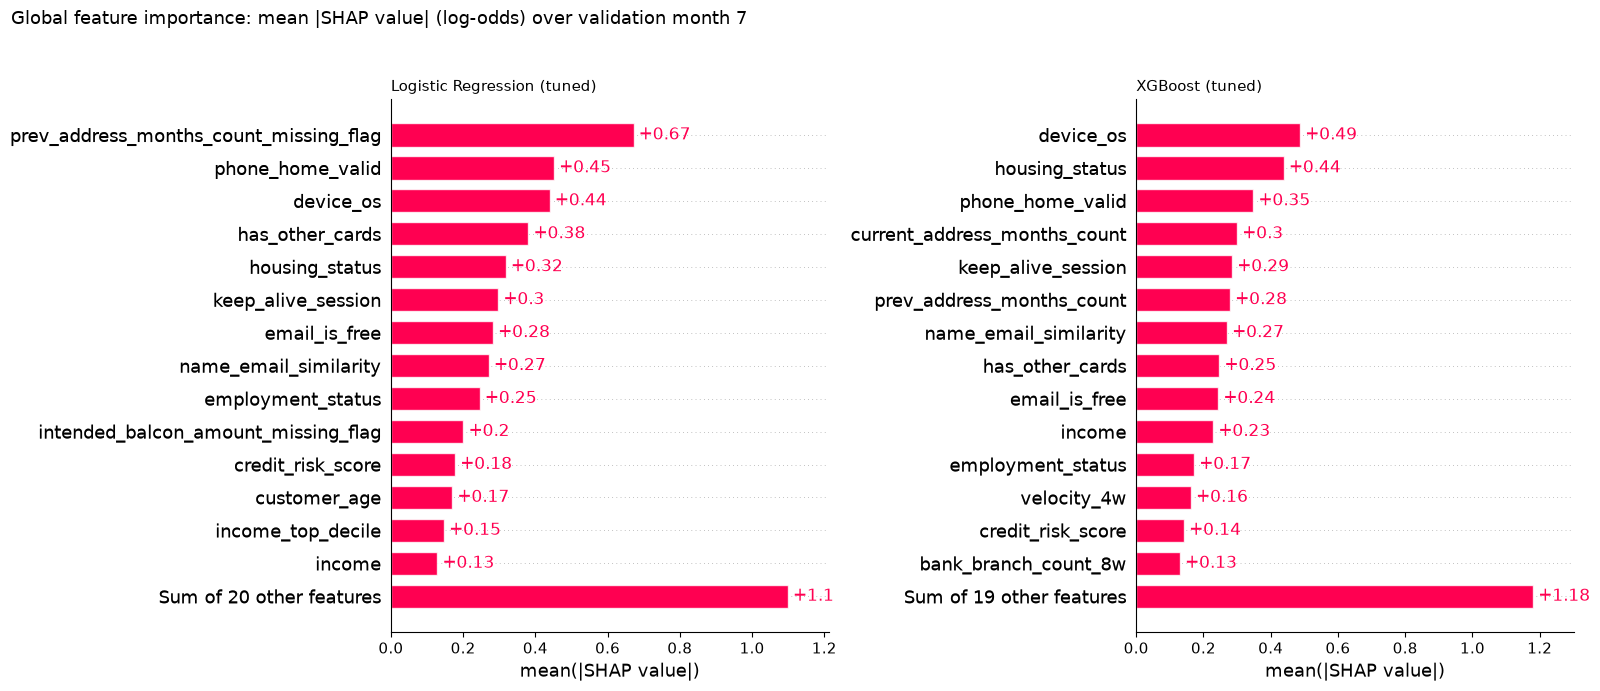

In [6]:
GLOBAL_MAX_DISPLAY = 15

fig, axes = plt.subplots(1, len(SHAP_MODELS), figsize=(16, 7))
for ax, name in zip(axes, SHAP_MODELS):
    shap.plots.bar(explanations[name], max_display=GLOBAL_MAX_DISPLAY, ax=ax, show=False)
    ax.set_title(name, fontsize=11, loc="left")
fig.suptitle("Global feature importance: mean |SHAP value| (log-odds) over validation month 7",
             x=0.01, ha="left", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

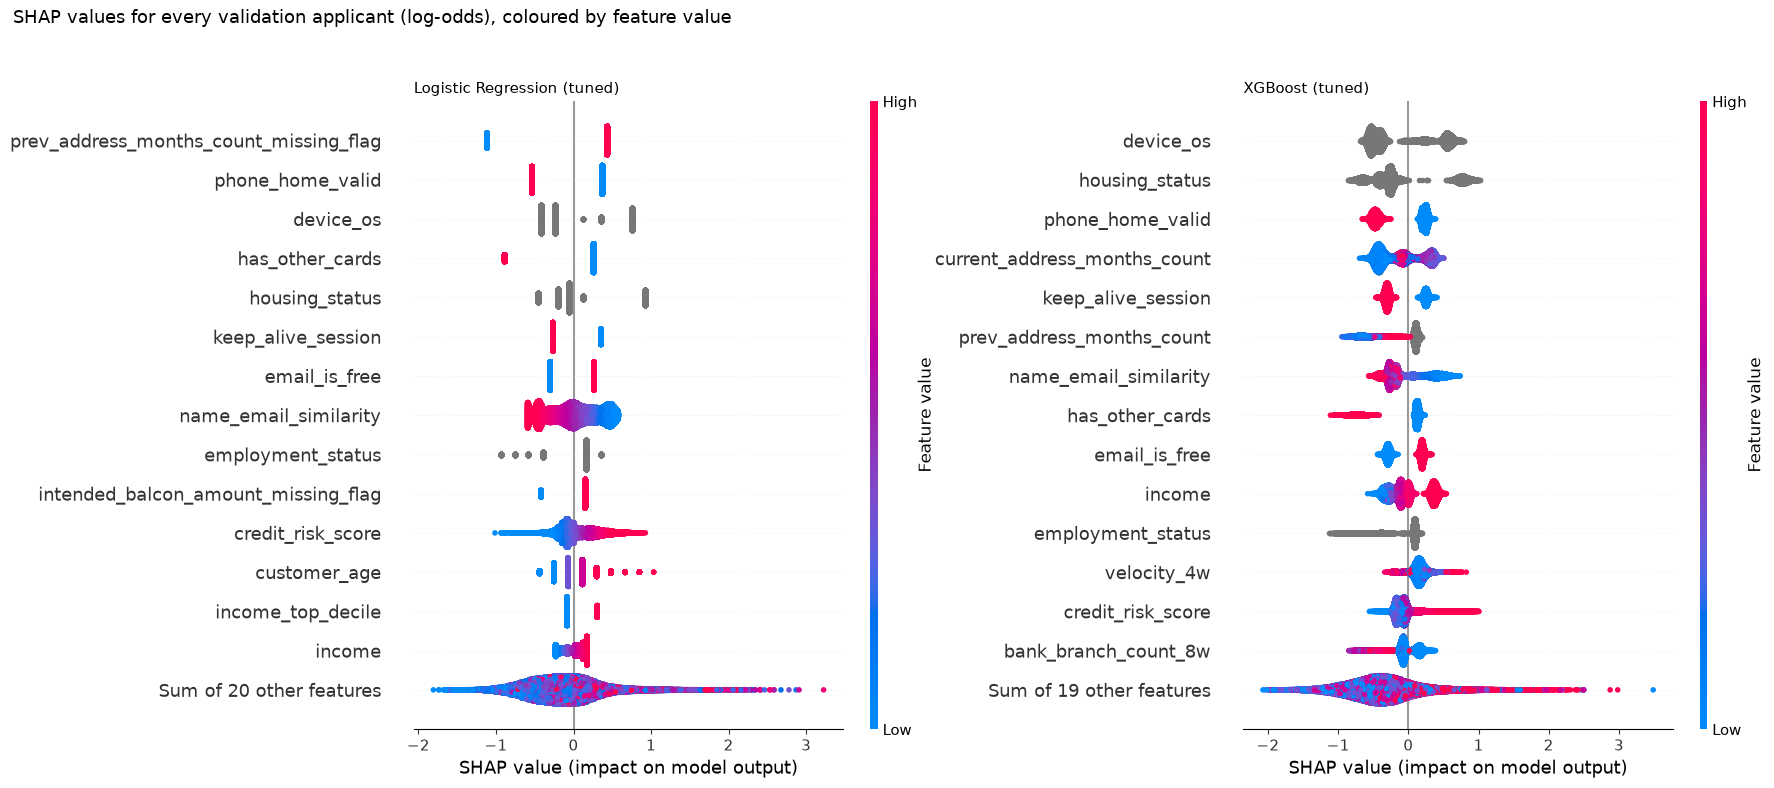

In [7]:
fig, axes = plt.subplots(1, len(SHAP_MODELS), figsize=(18, 8))
for ax, name in zip(axes, SHAP_MODELS):
    # plot_size=None keeps beeswarm from resizing the shared figure
    # Categorical features have no numeric values, so their all-NaN colour scaling warns harmlessly
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        shap.plots.beeswarm(explanations[name], max_display=GLOBAL_MAX_DISPLAY, ax=ax, plot_size=None, show=False)
    ax.set_title(name, fontsize=11, loc="left")
fig.suptitle("SHAP values for every validation applicant (log-odds), coloured by feature value",
             x=0.01, ha="left", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

In [8]:
# Mean |SHAP| side by side, ranked by the average across the two models
global_importance = pd.DataFrame({name: shap_values[name].abs().mean() for name in SHAP_MODELS})
global_importance["Average"] = global_importance.mean(axis=1)
global_importance = global_importance.sort_values("Average", ascending=False)
global_importance.head(GLOBAL_MAX_DISPLAY).round(3)

,Logistic Regression (tuned),XGBoost (tuned),Average
device_os,0.440,0.487,0.463
phone_home_valid,0.452,0.348,0.400
housing_status,0.318,0.439,0.378
prev_address_months_count_missing_flag,0.672,0.061,0.367
has_other_cards,0.381,0.247,0.314
keep_alive_session,0.297,0.285,0.291
name_email_similarity,0.271,0.270,0.270
email_is_free,0.283,0.244,0.263
employment_status,0.246,0.172,0.209
income,0.128,0.229,0.179


- Both models lean on largely the same signals: `device_os`, `housing_status`, `phone_home_valid`, `keep_alive_session`, `has_other_cards`, `name_email_similarity` and `email_is_free` are near the top for each.
- The biggest difference is how they use address history. LR's strongest feature is `prev_address_months_count_missing_flag` (0.67), which XGBoost barely uses (0.06). XGBoost instead uses `prev_address_months_count` and `current_address_months_count` directly (0.28-0.30): trees handle `NaN` natively and can pick up non-linear patterns in the month counts, so the missing flag adds little for them.
- Direction (beeswarm): a valid home phone, other cards and a keep-alive session push towards non-fraud; a free email, low name-email similarity and a high credit risk score push towards fraud.
- `customer_age` is mid-ranking (0.17 LR, 0.12 XGBoost), which fits `04`, where removing it cost little performance. It is one contributor to the older-applicant FPR gap, not the dominant one.
- `income_top_decile` only exists for LR (0.15), adding to `income` (0.13) for the top income band.

## Explaining Individual Predictions

Four validation cases are picked for each tuned model, using that model's own 5% FPR threshold:
- **Highest-scoring true positive:** a clear-cut catch.
- **Borderline false positive:** the non-fraud applicant with the lowest score that still clears the threshold.
- **Lowest-scoring false negative:** the fraud the model was most confident wasn't fraud.
- **Highest-scoring false positive aged 50+:** the older legitimate applicant the model is most sure is fraud, to see case by case what drives the FPR gap.

Each model has its own threshold and its own mistakes, so the logistic regression and XGBoost plots for a case are usually different applicants. Their SHAP values are taken from the saved arrays above, so nothing is recomputed.

In [9]:
def pick_cases(scores, threshold):
    # Positions in the validation month of the four cases, using this model's own threshold
    flagged = scores >= threshold
    fraud = y_val_array == 1
    older = val_age >= AGE_GROUP_CUTOFF

    def highest_scoring(mask):
        positions = np.flatnonzero(mask)
        return positions[np.argmax(scores[positions])]

    def lowest_scoring(mask):
        positions = np.flatnonzero(mask)
        return positions[np.argmin(scores[positions])]

    return {
        "Highest-scoring true positive": highest_scoring(fraud & flagged),
        "Borderline false positive": lowest_scoring(~fraud & flagged),
        "Lowest-scoring false negative": lowest_scoring(fraud & ~flagged),
        f"Highest-scoring false positive aged {AGE_GROUP_CUTOFF}+": highest_scoring(~fraud & flagged & older),
    }


shap_cases = {name: pick_cases(val_scores[name], thresholds[name]) for name in SHAP_MODELS}

summary_rows = []
for name, cases in shap_cases.items():
    for case, position in cases.items():
        summary_rows.append({
            "case": case,
            "model": name,
            "val_row": X_val_xgb.index[position],
            "customer_age": val_age[position],
            "fraud_bool": y_val_array[position],
            "score": val_scores[name][position],
            "threshold": thresholds[name],
        })

shap_case_summary = pd.DataFrame(summary_rows).set_index(["case", "model"])
shap_case_summary.sort_index(level="case", sort_remaining=False).round(4)

val_row  \
case                                    model                                  
Borderline false positive               Logistic Regression (tuned)   990934   
                                        XGBoost (tuned)               940987   
Highest-scoring false positive aged 50+ Logistic Regression (tuned)   953167   
                                        XGBoost (tuned)               907882   
Highest-scoring true positive           Logistic Regression (tuned)   945854   
                                        XGBoost (tuned)               938291   
Lowest-scoring false negative           Logistic Regression (tuned)   962445   
                                        XGBoost (tuned)               981016   

                                                                     customer_age  \
case                                    model                                       
Borderline false positive               Logistic Regression (tuned)            30   
                                        XGBoost (tuned)                        50   
Highest-scoring false positive aged 50+ Logistic Regression (tuned)            60   
                                        XGBoost (tuned)                        60   
Highest-scoring true positive           Logistic Regression (tuned)            70   
                                        XGBoost (tuned)                        30   
Lowest-scoring false negative           Logistic Regression (tuned)            50   
                                        XGBoost (tuned)                        30   

                                                                     fraud_bool  \
case                                    model                                     
Borderline false positive               Logistic Regression (tuned)           0   
                                        XGBoost (tuned)                       0   
Highest-scoring false positive aged 50+ Logistic Regression (tuned)           0   
                                        XGBoost (tuned)                       0   
Highest-scoring true positive           Logistic Regression (tuned)           1   
                                        XGBoost (tuned)                       1   
Lowest-scoring false negative           Logistic Regression (tuned)           1   
                                        XGBoost (tuned)                       1   

                                                                      score  \
case                                    model                                 
Borderline false positive               Logistic Regression (tuned)  0.0329   
                                        XGBoost (tuned)              0.0784   
Highest-scoring false positive aged 50+ Logistic Regression (tuned)  0.5181   
                                        XGBoost (tuned)              0.7934   
Highest-scoring true positive           Logistic Regression (tuned)  0.8093   
                                        XGBoost (tuned)              0.9605   
Lowest-scoring false negative           Logistic Regression (tuned)  0.0002   
                                        XGBoost (tuned)              0.0008   

                                                                     threshold  
case                                    model                                   
Borderline false positive               Logistic Regression (tuned)     0.0329  
                                        XGBoost (tuned)                 0.0784  
Highest-scoring false positive aged 50+ Logistic Regression (tuned)     0.0329  
                                        XGBoost (tuned)                 0.0784  
Highest-scoring true positive           Logistic Regression (tuned)     0.0329  
                                        XGBoost (tuned)                 0.0784  
Lowest-scoring false negative           Logistic Regression (tuned)     0.0329  
                                        XGBoost (tuned)           

Each plot is a `shap.plots.waterfall` in log-odds. It starts at the model's average output, E[f(X)], each feature pushes toward fraud (red) or non-fraud (blue), and it ends at the case's output, f(x). The dashed line is the decision threshold: a case is flagged when f(x) is to its right.

`shap.plots.waterfall` can only draw on a figure of its own, so each waterfall is rendered separately and the images are laid out in one grid: one row per case, one column per model.

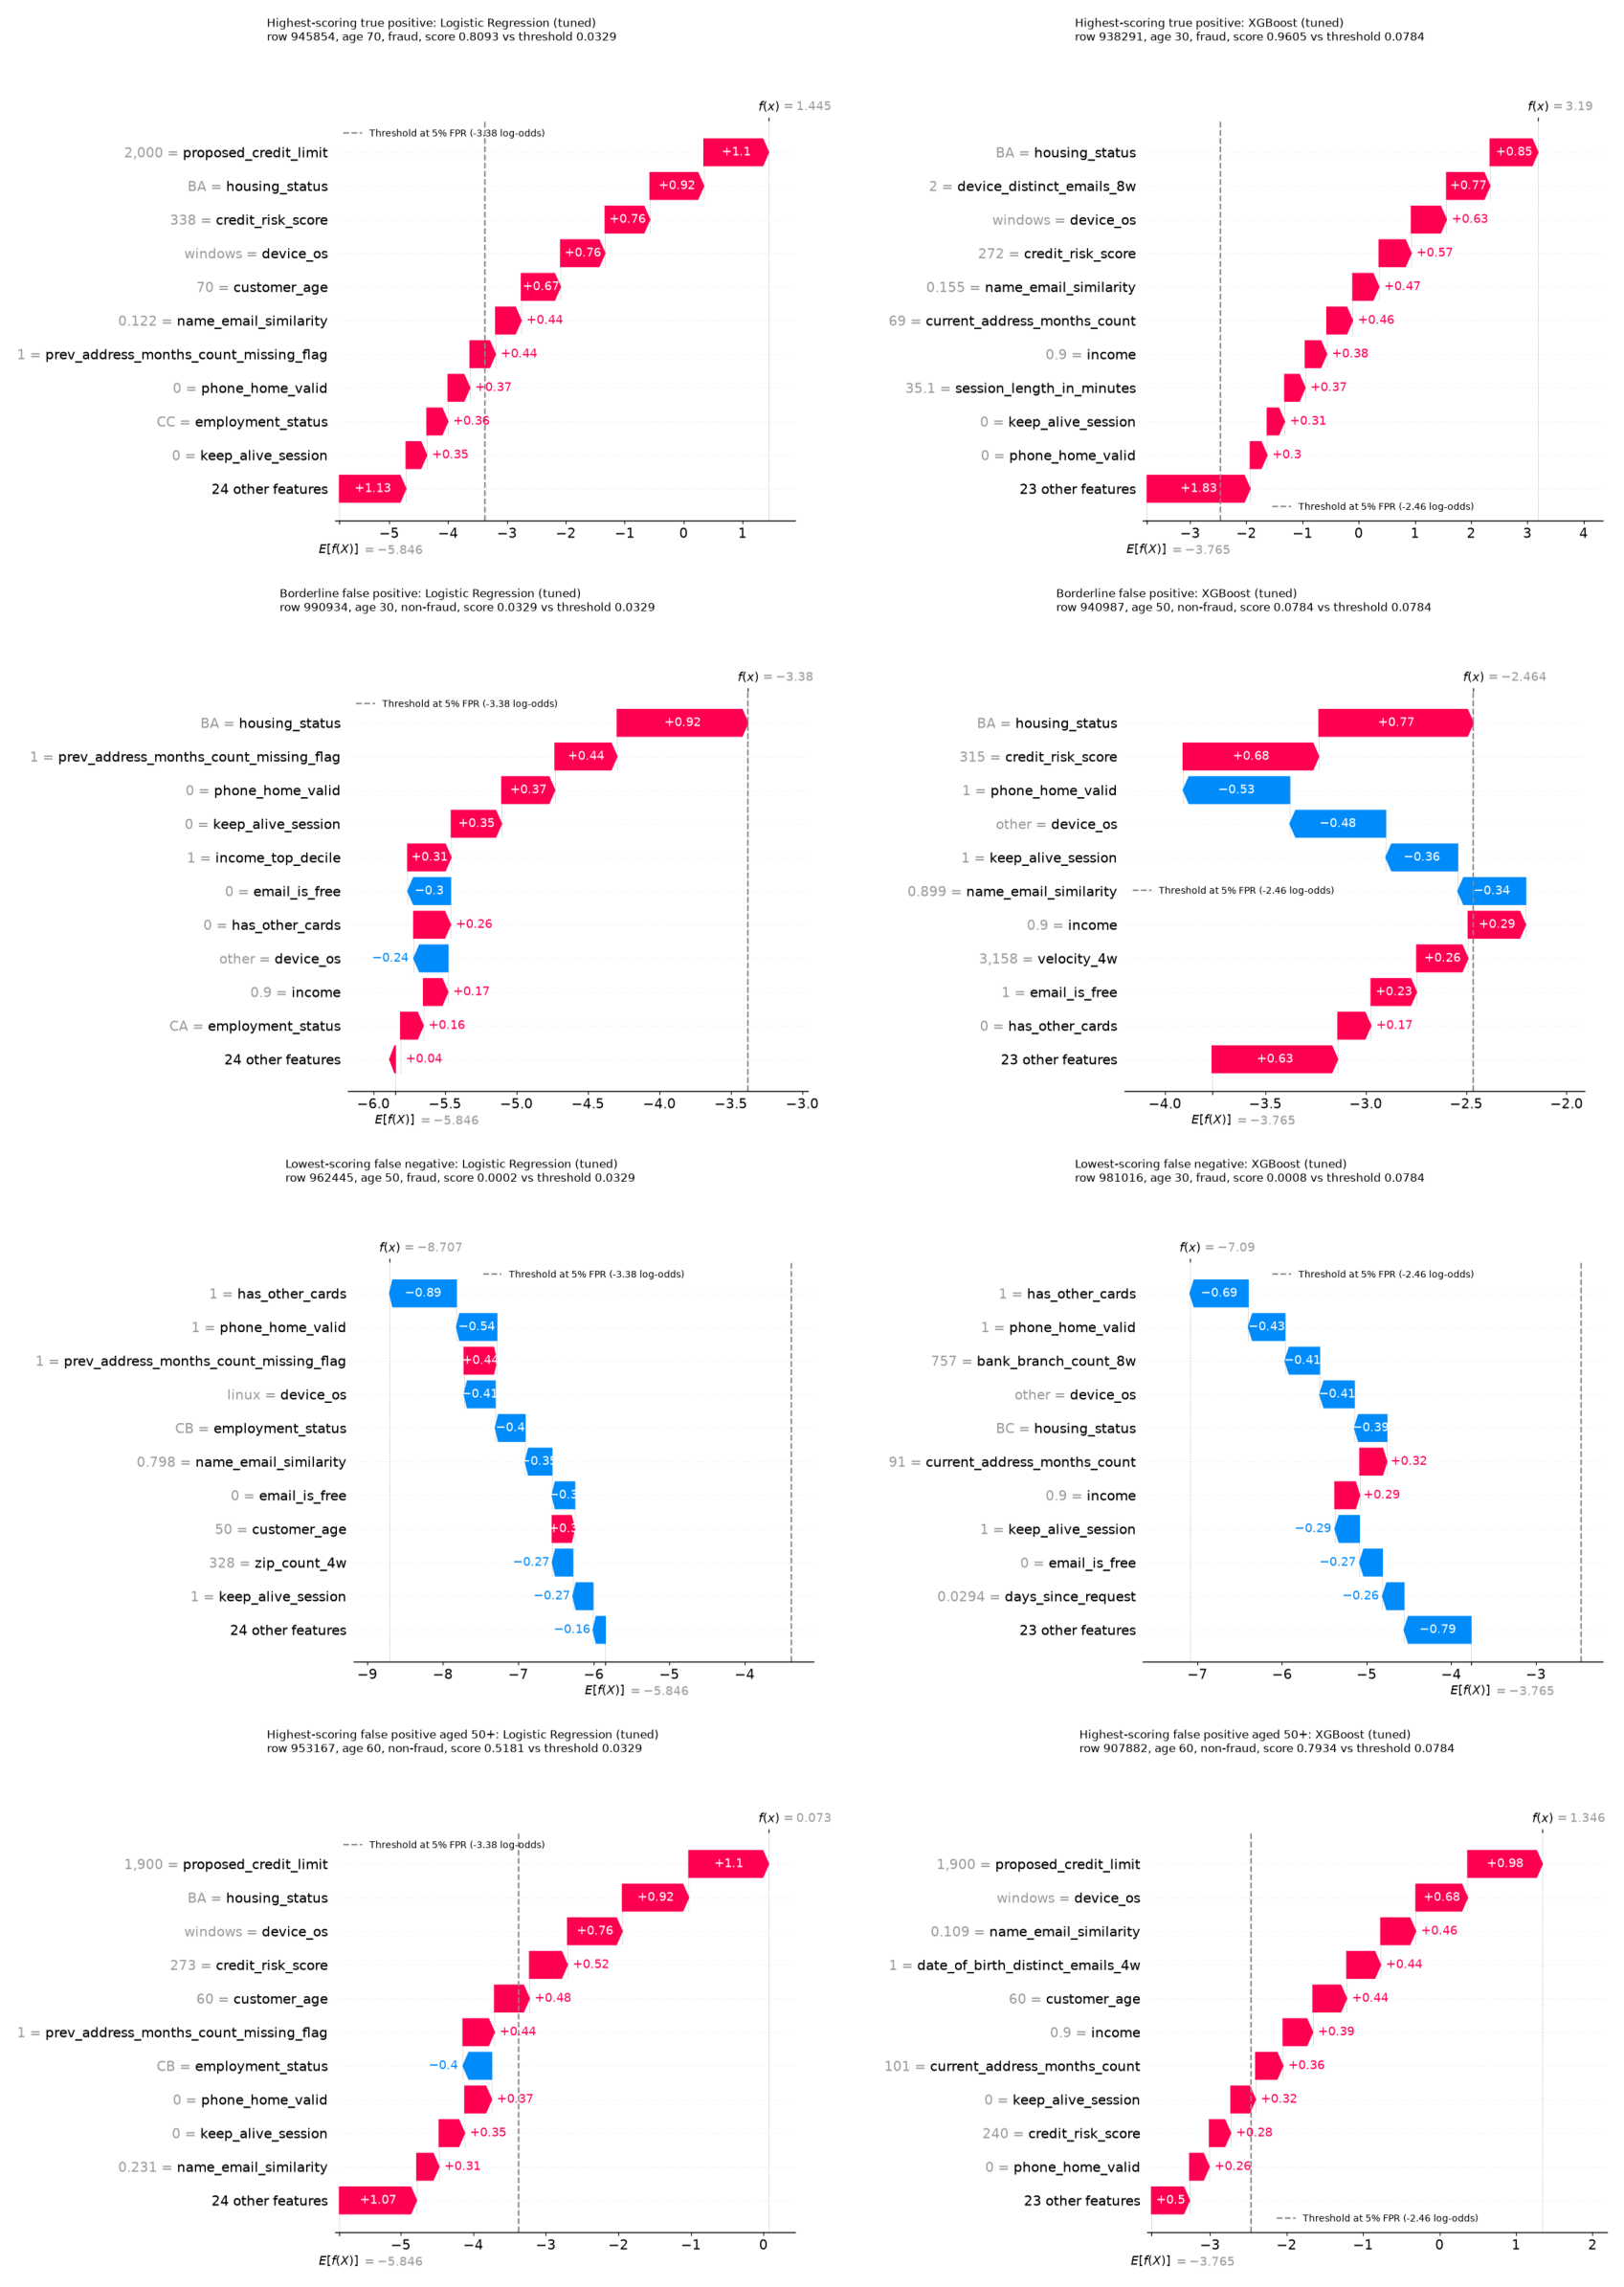

In [10]:
SHAP_MAX_DISPLAY = 11  # the 10 largest contributions, plus one bar summing the rest


def add_threshold_line(fig, threshold):
    # Widen every axis together so the threshold is in view: waterfall's E[f(X)] and f(x) labels sit on twin axes
    # that only stay aligned with the bars if all of them share the same limits
    ax = fig.axes[0]
    threshold_log_odds = log_odds(threshold)

    lo, hi = ax.get_xlim()
    pad = 0.05 * (max(hi, threshold_log_odds) - min(lo, threshold_log_odds))
    new_lo = min(lo, threshold_log_odds - pad)
    new_hi = max(hi, threshold_log_odds + pad)
    for axis in fig.axes:
        axis.set_xlim(new_lo, new_hi)

    label = f"Threshold at {TARGET_FPR:.0%} FPR ({threshold_log_odds:.2f} log-odds)"
    line = ax.axvline(threshold_log_odds, color=REFERENCE_COLOR, linewidth=1.5, linestyle="--", label=label)
    ax.legend(handles=[line], loc="best", frameon=False, fontsize=9)


def render_waterfall(name, case, position):
    outcome = "fraud" if y_val_array[position] else "non-fraud"
    title = (f"{case}: {name}\n"
             f"row {X_val_xgb.index[position]}, age {val_age[position]}, {outcome}, "
             f"score {val_scores[name][position]:.4f} vs threshold {thresholds[name]:.4f}")

    fig = plt.figure()
    shap.plots.waterfall(explanations[name][position], max_display=SHAP_MAX_DISPLAY, show=False)
    add_threshold_line(fig, thresholds[name])
    fig.suptitle(title, x=0.01, ha="left", y=1.08, fontsize=11)

    # waterfall needs a figure of its own, so render it to an image that can be placed in the grid
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=110, bbox_inches="tight")
    plt.close(fig)
    buffer.seek(0)
    return plt.imread(buffer)


case_names = list(shap_cases[SHAP_MODELS[0]])
fig, axes = plt.subplots(len(case_names), len(SHAP_MODELS), figsize=(9 * len(SHAP_MODELS), 6 * len(case_names)))
for row, case in enumerate(case_names):
    for col, name in enumerate(SHAP_MODELS):
        ax = axes[row, col]
        ax.imshow(render_waterfall(name, case, shap_cases[name][case]))
        ax.axis("off")
fig.tight_layout()
plt.show()

- The high-scoring cases (the top true positives and the older false positives) share a profile: a `windows` device in all four, and a high `proposed_credit_limit` (1,900-2,000), `housing_status` BA and a high `credit_risk_score` each in three of the four. XGBoost's top true positive is driven by `housing_status` BA and `device_distinct_emails_8w` = 2 instead of the credit limit.
- The older false positives (both aged 60) look very much like the true positives to the models, which is why they are flagged with high confidence (scores 0.52 LR, 0.79 XGBoost). `customer_age` adds about +0.45 log-odds for each, a real push but under half the credit limit's (+1.10 LR, +0.98 XGBoost).
- The missed frauds look like typical legitimate applicants: other cards and a valid home phone are the strongest non-fraud signals for both models, helped by a `linux` or `other` device, and they outweigh everything else.
- The borderline false positives sit right at the threshold by construction; a small change in any one feature would flip them. For both models, `housing_status` BA is their largest push towards fraud.